# Nisansala Ruwanpathirana | Associate Data Analyst Assessment
**Part 1 - Cargills Retail Apparel - Data Cleaning & Preprocessing**

This cleans the six raw tables in `Retail_Apparel_Data_v1.xlsx` before KPI/insight work.

In [1]:
import pandas as pd
import numpy as np

pd.set_option("display.max_columns", None)

RAW_PATH = "Retail_Apparel_Data_v1.xlsx"
xls = pd.ExcelFile(RAW_PATH)

products_raw      = pd.read_excel(xls, "products")
transactions_raw  = pd.read_excel(xls, "transactions")
stores_raw        = pd.read_excel(xls, "stores")
foot_traffic_raw  = pd.read_excel(xls, "daily_foot_traffic")
inventory_raw     = pd.read_excel(xls, "inventory_snapshot")
promo_raw         = pd.read_excel(xls, "promo_calendar")

print("Row counts:", {n: len(df) for n, df in
      [("products", products_raw), ("transactions", transactions_raw), ("stores", stores_raw),
       ("foot_traffic", foot_traffic_raw), ("inventory", inventory_raw), ("promo", promo_raw)]})

Row counts: {'products': 18, 'transactions': 20774, 'stores': 9, 'foot_traffic': 1464, 'inventory': 882, 'promo': 4}


## 1. Data Quality Audit
Before fixing anything, quantify the problems: 
null values, duplicate rows, and dtype issues per table.

In [2]:
def audit(df, name):
    print(f"\n=== {name} ===")
    print("shape:", df.shape)
    nulls = df.isna().sum()
    print("nulls:\n", nulls[nulls > 0])
    print("exact duplicate rows:", df.duplicated().sum())

for name, df in [("products", products_raw), ("transactions", transactions_raw), ("stores", stores_raw),
                  ("foot_traffic", foot_traffic_raw), ("inventory", inventory_raw), ("promo", promo_raw)]:
    audit(df, name)


=== products ===
shape: (18, 5)
nulls:
 category    2
dtype: int64
exact duplicate rows: 0

=== transactions ===
shape: (20774, 14)
nulls:
 discount_pct    437
customer_id       9
dtype: int64
exact duplicate rows: 347

=== stores ===
shape: (9, 10)
nulls:
 store_close_date    8
dtype: int64
exact duplicate rows: 0

=== foot_traffic ===
shape: (1464, 3)
nulls:
 Series([], dtype: int64)
exact duplicate rows: 0

=== inventory ===
shape: (882, 4)
nulls:
 Series([], dtype: int64)
exact duplicate rows: 0

=== promo ===
shape: (4, 7)
nulls:
 Series([], dtype: int64)
exact duplicate rows: 0


## 2. Clean `stores`
`store_open_date` / `store_close_date` are stored as text; parsing them lets us later normalize any
store-level KPI by "days open" rather than raw calendar days - important since ST04 closed and ST09
opened mid-period, so raw totals would unfairly penalize/favor them.

In [3]:
stores = stores_raw.copy()
stores["store_open_date"]  = pd.to_datetime(stores["store_open_date"], format="%Y-%m-%d")
stores["store_close_date"] = pd.to_datetime(stores["store_close_date"], format="%Y-%m-%d", errors="coerce")
stores["is_active"] = stores["store_close_date"].isna()

print(stores[["store_id", "store_name", "store_open_date", "store_close_date", "is_active"]])

  store_id         store_name store_open_date store_close_date  is_active
0     ST01  Downtown Flagship      2019-03-15              NaT       True
1     ST02     Riverside Mall      2020-08-01              NaT       True
2     ST05       Sunset Plaza      2021-02-11              NaT       True
3     ST03    Lakeview Center      2018-05-20              NaT       True
4     ST04       Union Square      2017-11-02       2025-04-30      False
5     ST09       Elmwood Gate      2025-04-01              NaT       True
6     ST06       Harbor Point      2019-09-30              NaT       True
7     ST07   Magnolia Commons      2022-01-17              NaT       True
8     ST08  Peachtree Corners      2020-06-05              NaT       True


## 3. Clean `products`
Two products (`P004` Cotton Tee, `P013` Leather Boots) are missing `category` in the master table.
I backfill using the mode of `category` recorded against that `product_id` in the
transactions table.

I also found **P001 and P010 are both named "Rain Jacket"** at different prices - a real trap: any
analysis that grouped/joined on `product_name` instead of the unique `product_id` would silently merge
two different SKUs. Rather than just flag this, we rename them to "Rain Jacket 1" / "Rain Jacket 2"
(ordered by `product_id` so the naming is stable on every rerun) so they're unambiguous in every
downstream table, chart, and dashboard.

In [4]:
products = products_raw.copy()

category_from_tx = (
    transactions_raw.dropna(subset=["category"])
    .groupby("product_id")["category"]
    .agg(lambda s: s.mode().iat[0])
)
missing_cat = products["category"].isna()
products.loc[missing_cat, "category"] = products.loc[missing_cat, "product_id"].map(category_from_tx)
print("Remaining missing categories:", products["category"].isna().sum())

assert products["product_id"].is_unique, "product_id should be unique -- safe join key"

dupe_names = products[products.duplicated(subset=["product_name"], keep=False)]
print("\nDuplicate product_name across different product_id (before rename):")
print(dupe_names[["product_id", "product_name", "cost_price"]])

# rename duplicate "Rain Jacket" SKUs so they're distinguishable everywhere downstream
rain_jacket_ids = products.loc[products["product_name"] == "Rain Jacket", "product_id"].sort_values().tolist()
rename_map = {rain_jacket_ids[0]: "Rain Jacket 1", rain_jacket_ids[1]: "Rain Jacket 2"}
products.loc[products["product_id"].isin(rename_map), "product_name"] = products["product_id"].map(rename_map)

print("\nAfter rename:")
print(products[products["product_id"].isin(rename_map)][["product_id", "product_name", "cost_price"]])

Remaining missing categories: 0

Duplicate product_name across different product_id (before rename):
   product_id product_name  cost_price
0        P001  Rain Jacket          45
10       P010  Rain Jacket          16

After rename:
   product_id   product_name  cost_price
0        P001  Rain Jacket 1          45
10       P010  Rain Jacket 2          16


## 4. Clean `transactions` - Step 1: drop unreliable column, remove exact duplicates
`Unnamed: 13` is a pre-computed revenue figure left in the file, but it was built before cleaning
(e.g. it doesn't handle the missing discount values consistently), so it is dropped and recomputed revenue
ourselves later from clean fields. 347 fully duplicated rows are founded (same values in every
column) - these are true duplicate log entries, not multi-item baskets, and are removed.

In [5]:
tx = transactions_raw.drop(columns=["Unnamed: 13"]).copy()

before = len(tx)
tx = tx.drop_duplicates()
print(f"Removed {before - len(tx)} exact duplicate rows -> {len(tx)} rows remain")

print("Unique transaction_id vs rows:", tx['transaction_id'].nunique(), "vs", len(tx),
      "-> multiple product lines per basket, this is expected and NOT an error")

Removed 347 exact duplicate rows -> 20427 rows remain
Unique transaction_id vs rows: 11796 vs 20427 -> multiple product lines per basket, this is expected and NOT an error


## 5. Clean `transactions` - Step 2: resolve the date-format contradiction
The assessment states `order_date` should be read as **DD/MM/YYYY** for the slash-formatted
rows. Before applying, it is validated against the data itself.

In [6]:
slash_dates = tx.loc[tx["order_date"].str.contains("/"), "order_date"]
parts = slash_dates.str.split("/", expand=True).astype(int)
parts.columns = ["component_1", "component_2", "year"]

print("If DD/MM/YYYY: component_2 (month) range ->", parts.component_2.min(), "-", parts.component_2.max())
print("Rows where that would be an invalid month (>12):", (parts.component_2 > 12).sum())
print("component_1 range (all rows):", parts.component_1.min(), "-", parts.component_1.max(),
      "<- matches dataset's Jan-Jun window, so component_1 = MONTH, not day")

iso_days = pd.to_datetime(tx.loc[tx["order_date"].str.contains("-"), "order_date"]).dt.day
print("ISO-format day-of-month spread (for comparison):", iso_days.min(), "-", iso_days.max())

If DD/MM/YYYY: component_2 (month) range -> 1 - 31
Rows where that would be an invalid month (>12): 2655
component_1 range (all rows): 1 - 6 <- matches dataset's Jan-Jun window, so component_1 = MONTH, not day
ISO-format day-of-month spread (for comparison): 1 - 31


----

**Decision:** the test above proves the slash-formatted dates are actually **MM/DD/YYYY**, not
DD/MM/YYYY as the brief states - testing DD/MM/YYYY produces thousands of invalid dates (month > 12),
while the first component never exceeds 6, matching this dataset's Jan-Jun 2025 window. We parse using
what the data shows, and flag this contradiction as worth raising with the assessor rather than
silently following an instruction that produces broken dates.

---

In [7]:
def parse_order_date(s: str) -> pd.Timestamp:
    """ISO rows are YYYY-MM-DD. Slash rows are MM/DD/YYYY (validated above, overriding the brief)."""
    if "-" in s:
        return pd.to_datetime(s, format="%Y-%m-%d")
    return pd.to_datetime(s, format="%m/%d/%Y")

tx["order_date"] = tx["order_date"].apply(parse_order_date)
print("Parsed date range:", tx["order_date"].min(), "to", tx["order_date"].max())
print("Nulls after parsing:", tx["order_date"].isna().sum())

Parsed date range: 2025-01-01 00:00:00 to 2025-06-30 00:00:00
Nulls after parsing: 0


## 6. Clean `transactions` - Step 3: standardize `store_name`
`store_name` has 40 text variants for 9 stores (case, whitespace, abbreviations like "Dwntwn
Flagship"). `store_id` is clean and consistent, so the messy text column are discarded the entirely and
re-derive `store_name` from the `stores` master table via `store_id`.

In [8]:
name_lookup = stores.set_index("store_id")["store_name"]
tx["store_name"] = tx["store_id"].map(name_lookup)

assert tx["store_name"].isna().sum() == 0, "unmapped store_id found"
print(tx[["store_id", "store_name"]].drop_duplicates().sort_values("store_id"))

     store_id         store_name
0        ST01  Downtown Flagship
8        ST02     Riverside Mall
15       ST03    Lakeview Center
20       ST04       Union Square
30       ST05       Sunset Plaza
42       ST06       Harbor Point
54       ST07   Magnolia Commons
62       ST08  Peachtree Corners
9795     ST09       Elmwood Gate


## 7. Clean `transactions` - Step 4: missing `discount_pct` and `customer_id`
437 rows are missing `discount_pct`. Rather than guess a value, we impute 0% (no discount applied)
and keep a `discount_missing_flag` column so this assumption stays auditable rather than hidden.
9 rows are missing `customer_id` - likely guest checkouts - flagged as `"GUEST-UNKNOWN"` so they're
still countable in transaction-level KPIs but excluded from customer-level analysis (e.g. loyalty).

In [9]:
tx["discount_missing_flag"] = tx["discount_pct"].isna()
tx["discount_pct"] = tx["discount_pct"].fillna(0.0)

tx["customer_id"] = tx["customer_id"].fillna("GUEST-UNKNOWN")

print("Rows with imputed discount:", tx["discount_missing_flag"].sum())
print("Guest-checkout rows:", (tx["customer_id"] == "GUEST-UNKNOWN").sum())

Rows with imputed discount: 428
Guest-checkout rows: 9


## 8. Clean `transactions` - Step 5: negative quantities are returns, not errors
329 rows have negative `quantity`. These are legitimate returns/refunds, not data entry mistakes -
deleting them would overstate net sales. Each row is tagged as `sale` or `return` with `txn_type`, then 
both `gross_revenue` (always positive, sales volume view) and `net_revenue` are computed (signed, the true
P&L view) so Part 2 can report returns as their own KPI (e.g. return rate by SKU/store) instead of
silently netting them away.

In [10]:
tx["txn_type"] = np.where(tx["quantity"] < 0, "return", "sale")

tx["gross_revenue"] = tx["quantity"].abs() * tx["unit_price"]
tx["net_revenue"]   = tx["quantity"] * tx["unit_price"] * (1 - tx["discount_pct"])

print(tx["txn_type"].value_counts())
print("Total net revenue:", round(tx["net_revenue"].sum(), 2))
print("Total gross revenue:", round(tx["gross_revenue"].sum(), 2))
print("Return rate (rows):", round((tx["txn_type"] == "return").mean() * 100, 2), "%")

txn_type
sale      20106
return      321
Name: count, dtype: int64
Total net revenue: 1649037.9
Total gross revenue: 1881519
Return rate (rows): 1.57 %


## 9. Clean remaining tables - `daily_foot_traffic`, `inventory_snapshot`, `promo_calendar`
These three tables had no nulls or duplicates in the audit - only their date columns need
parsing from text to datetime so they can be joined/filtered by period in Part 2.

In [11]:
foot_traffic = foot_traffic_raw.copy()
foot_traffic["date"] = pd.to_datetime(foot_traffic["date"], format="%Y-%m-%d")

inventory = inventory_raw.copy()
inventory["snapshot_date"] = pd.to_datetime(inventory["snapshot_date"], format="%Y-%m-%d")

promo = promo_raw.copy()
promo["start_date"] = pd.to_datetime(promo["start_date"], format="%Y-%m-%d")
promo["end_date"]   = pd.to_datetime(promo["end_date"], format="%Y-%m-%d")

print(foot_traffic["date"].min(), "-", foot_traffic["date"].max())
print(inventory["snapshot_date"].unique())
print(promo[["promo_name", "category", "discount_pct", "start_date", "end_date", "store_id"]])

2025-01-01 00:00:00 - 2025-06-30 00:00:00
<DatetimeArray>
['2025-01-31 00:00:00', '2025-02-28 00:00:00', '2025-03-31 00:00:00',
 '2025-04-30 00:00:00', '2025-05-31 00:00:00', '2025-06-30 00:00:00']
Length: 6, dtype: datetime64[ns]
               promo_name   category  discount_pct start_date   end_date  \
0  Spring Outerwear Event  Outerwear          0.25 2025-03-01 2025-03-21   
1  Spring Outerwear Event  Outerwear          0.25 2025-03-01 2025-03-21   
2  Spring Outerwear Event  Outerwear          0.25 2025-03-01 2025-03-21   
3  Spring Outerwear Event  Outerwear          0.25 2025-03-01 2025-03-21   

  store_id  
0     ST01  
1     ST03  
2     ST06  
3     ST08  


## 10. Referential integrity check
Confirm every `store_id` and `product_id` in `transactions` actually exists in the `stores` and
`products` master tables - if this fails, downstream joins would silently drop rows. We also
re-apply the `store_name` mapping defensively right before building the final table, so this
gives correct results even if run alone.

In [12]:
orphan_stores   = set(tx["store_id"])   - set(stores["store_id"])
orphan_products = set(tx["product_id"]) - set(products["product_id"])

print("Orphan store_ids:", orphan_stores if orphan_stores else "none - OK")
print("Orphan product_ids:", orphan_products if orphan_products else "none - OK")

# re-apply in case tx was rebuilt since Cell 15 last ran (defensive, avoids stale-state bugs)
tx["store_name"] = tx["store_id"].map(name_lookup)

# transactions' own product_name/category/region columns are superseded by the clean master tables
tx_final = tx.drop(columns=["product_name", "category", "region"]).merge(
    products[["product_id", "product_name", "category"]], on="product_id", how="left"
).merge(
    stores[["store_id", "region"]], on="store_id", how="left"
)
print(tx_final.shape)
tx_final.head()

Orphan store_ids: none - OK
Orphan product_ids: none - OK
(20427, 17)


,transaction_id,order_date,store_id,store_name,product_id,quantity,unit_price,discount_pct,customer_id,loyalty_member,discount_missing_flag,txn_type,gross_revenue,net_revenue,product_name,category,region
0,700001,2025-01-01,ST01,Downtown Flagship,P014,2,24,0.00,C02953,1,False,sale,48,48.0,Leather Belt,Accessories,Northeast
1,700001,2025-01-01,ST01,Downtown Flagship,P011,1,89,0.00,C02953,1,False,sale,89,89.0,Running Shoes,Footwear,Northeast
2,700001,2025-01-01,ST01,Downtown Flagship,P004,3,18,0.10,C02953,1,False,sale,54,48.6,Cotton Tee,Tops,Northeast
3,700002,2025-01-01,ST01,Downtown Flagship,P004,1,18,0.05,C01683,0,False,sale,18,17.1,Cotton Tee,Tops,Northeast
4,700003,2025-01-01,ST01,Downtown Flagship,P006,2,54,0.00,C03186,0,False,sale,108,108.0,Knit Sweater,Accessories,Northeast


## 11. Save cleaned tables
Persist all cleaned tables to CSV so they can be reused directly.

In [13]:
tx_final.to_csv("transactions_clean.csv", index=False)
products.to_csv("products_clean.csv", index=False)
stores.to_csv("stores_clean.csv", index=False)
foot_traffic.to_csv("foot_traffic_clean.csv", index=False)
inventory.to_csv("inventory_clean.csv", index=False)
promo.to_csv("promo_clean.csv", index=False)

print("Cleaned files saved:")
print("- transactions_clean.csv:", tx_final.shape)
print("- products_clean.csv:", products.shape)
print("- stores_clean.csv:", stores.shape)
print("- foot_traffic_clean.csv:", foot_traffic.shape)
print("- inventory_clean.csv:", inventory.shape)
print("- promo_clean.csv:", promo.shape)

Cleaned files saved:
- transactions_clean.csv: (20427, 17)
- products_clean.csv: (18, 5)
- stores_clean.csv: (9, 11)
- foot_traffic_clean.csv: (1464, 3)
- inventory_clean.csv: (882, 4)
- promo_clean.csv: (4, 7)


## Summary
Cleaned 20,774 raw transaction rows down to 20,427 valid rows (347 exact duplicates removed), fixed a date-format contradiction in the brief, standardized store names, backfilled missing product categories, and separated returns from sales. All six cleaned tables are saved as CSVs, ready for KPI analysis.

# PART 2: KPI Analysis & the 10 Business Questions
Continuing with the cleaned tables above (`tx_final`, `stores`, `products`, `foot_traffic`, `inventory`,
`promo`).

## Add cost/margin data
Every question from here on needs margin (central to SKU, pricing, and store-performance decisions).
We merge in `cost_price` once and compute `net_margin` per transaction line.

In [14]:
import matplotlib.pyplot as plt
from scipy import stats

tx_final = tx_final.merge(products[["product_id", "cost_price"]], on="product_id", how="left")
tx_final["net_margin"] = (tx_final["unit_price"] - tx_final["cost_price"]) * tx_final["quantity"] * (1 - tx_final["discount_pct"])

print(tx_final[["product_id", "product_name", "unit_price", "cost_price", "net_margin"]].head())

  product_id   product_name  unit_price  cost_price  net_margin
0       P014   Leather Belt          24           9        30.0
1       P011  Running Shoes          89          38        51.0
2       P004     Cotton Tee          18           6        32.4
3       P004     Cotton Tee          18           6        11.4
4       P006   Knit Sweater          54          22        64.0


## Q1. How would you assess overall store performance?
Raw revenue unfairly favors big/busy stores. A composite score is built from three normalized (z-scored) metrics that control for size and traffic: **revenue per sq ft per day open** (accounts for ST04 closing and ST09 opening mid-period), **conversion rate** (transactions ÷ foot traffic), and **margin %**.

In [15]:
PERIOD_START, PERIOD_END = pd.Timestamp("2025-01-01"), pd.Timestamp("2025-06-30")

stores["days_open"] = (
    stores["store_close_date"].fillna(PERIOD_END).clip(upper=PERIOD_END)
    - stores["store_open_date"].clip(lower=PERIOD_START)
).dt.days + 1

sales = tx_final[tx_final.txn_type == "sale"]
returns = tx_final[tx_final.txn_type == "return"]

store_kpi = tx_final.groupby("store_id").agg(
    net_revenue=("net_revenue", "sum"),
    gross_revenue=("gross_revenue", "sum"),
    net_margin=("net_margin", "sum"),
    n_transactions=("transaction_id", "nunique"),
).reset_index()

return_rev = returns.groupby("store_id")["gross_revenue"].sum().rename("return_gross_revenue")
store_kpi = store_kpi.merge(return_rev, on="store_id", how="left").fillna({"return_gross_revenue": 0})
store_kpi["return_rate_pct"] = (store_kpi["return_gross_revenue"] / store_kpi["gross_revenue"] * 100).round(2)

store_kpi = store_kpi.merge(stores[["store_id", "store_name", "region", "store_sqft", "days_open", "store_manager"]], on="store_id")
store_kpi["revenue_per_sqft_per_day"] = (store_kpi["net_revenue"] / store_kpi["store_sqft"] / store_kpi["days_open"]).round(2)
store_kpi["aov"] = (store_kpi["net_revenue"] / store_kpi["n_transactions"]).round(2)
store_kpi["margin_pct"] = (store_kpi["net_margin"] / store_kpi["net_revenue"] * 100).round(1)

ft_total = foot_traffic.groupby("store_id")["foot_traffic"].sum().rename("total_foot_traffic")
store_kpi = store_kpi.merge(ft_total, on="store_id")
store_kpi["conversion_rate_pct"] = (store_kpi["n_transactions"] / store_kpi["total_foot_traffic"] * 100).round(2)

store_kpi["z_rev_per_sqft_day"] = stats.zscore(store_kpi["revenue_per_sqft_per_day"])
store_kpi["z_conversion"] = stats.zscore(store_kpi["conversion_rate_pct"])
store_kpi["z_margin_pct"] = stats.zscore(store_kpi["margin_pct"])
store_kpi["composite_score"] = ((store_kpi["z_rev_per_sqft_day"] + store_kpi["z_conversion"] + store_kpi["z_margin_pct"]) / 3).round(2)

store_kpi = store_kpi.sort_values("composite_score", ascending=False)
store_kpi[["store_id", "store_name", "region", "net_revenue", "revenue_per_sqft_per_day",
           "conversion_rate_pct", "margin_pct", "return_rate_pct", "composite_score"]].round(2)

,store_id,store_name,region,net_revenue,revenue_per_sqft_per_day,conversion_rate_pct,margin_pct,return_rate_pct,composite_score
8,ST09,Elmwood Gate,Midwest,136940.95,0.27,5.84,56.5,1.22,1.72
6,ST07,Magnolia Commons,South,180987.35,0.17,5.22,56.5,1.35,0.71
1,ST02,Riverside Mall,Northeast,195894.75,0.17,4.59,56.5,1.74,0.47
7,ST08,Peachtree Corners,South,214493.05,0.19,4.89,56.4,1.99,0.33
2,ST03,Lakeview Center,Midwest,194608.60,0.20,4.83,56.3,1.98,-0.02
3,ST04,Union Square,Midwest,114344.70,0.13,4.02,56.4,2.00,-0.47
0,ST01,Downtown Flagship,Northeast,237914.85,0.15,4.05,56.3,1.66,-0.71
4,ST05,Sunset Plaza,West,215421.15,0.13,2.79,56.4,3.16,-0.93
5,ST06,Harbor Point,West,158432.50,0.13,3.44,56.3,1.77,-1.09


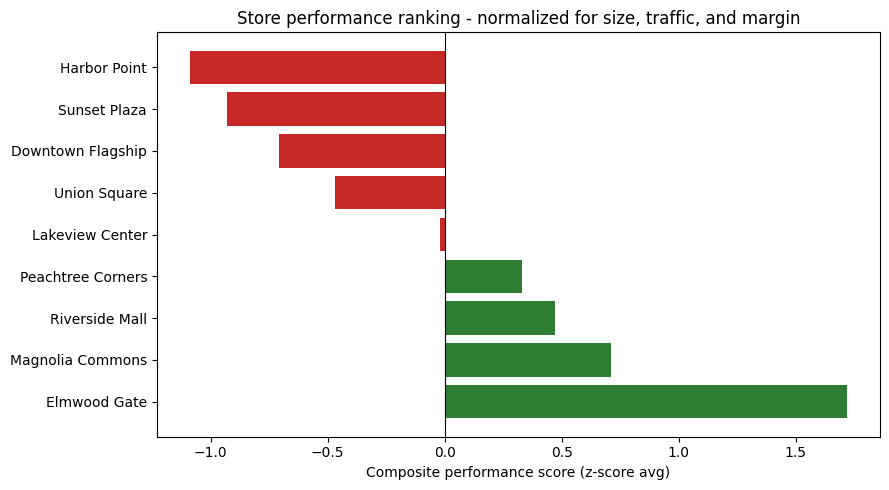

In [16]:
fig, ax = plt.subplots(figsize=(9, 5))
colors = ["#2e7d32" if v >= 0 else "#c62828" for v in store_kpi["composite_score"]]
ax.barh(store_kpi["store_name"], store_kpi["composite_score"], color=colors)
ax.set_xlabel("Composite performance score (z-score avg)")
ax.set_title("Store performance ranking - normalized for size, traffic, and margin")
ax.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

----

### Overall store performance

Instead of just looking at total sales (which favors big stores), I built a fairness-adjusted score using revenue per square foot per day, conversion rate, and margin. 

Result: ST09 and ST07 top the list; ST05 and ST06 trail.

----

## Q2. What distinguishes a genuine underlying problem from a temporary bad month?
For each store, look at the **trend slope** across all 6 months (linear regression) vs. any single month's **z-score deviation**. A store with a steep negative slope has a structural problem; a store with one low-z month but a flat/positive slope just had a bad month. Note: ST04 (4 months, closed end-April) and ST09 (3 months, opened April) have small samples - their trend slopes are noisier and flagged accordingly.

In [17]:
tx_final["month"] = tx_final["order_date"].dt.to_period("M")
monthly = tx_final.groupby(["store_id", "month"])["net_revenue"].sum().reset_index()
monthly = monthly.sort_values(["store_id", "month"]).reset_index(drop=True)

pieces = []
for store_id, g in monthly.groupby("store_id"):
    g = g.copy()
    mean_, std_ = g["net_revenue"].mean(), g["net_revenue"].std()
    g["z_score"] = (g["net_revenue"] - mean_) / std_
    x = np.arange(len(g))
    slope, _ = np.polyfit(x, g["net_revenue"], 1)
    g["trend_slope"] = slope
    g["n_months"] = len(g)
    pieces.append(g)
monthly_trend = pd.concat(pieces, ignore_index=True)

trend_summary = monthly_trend.groupby("store_id").agg(
    avg_monthly_revenue=("net_revenue", "mean"),
    trend_slope=("trend_slope", "first"),
    worst_month_z=("z_score", "min"),
    n_months=("n_months", "first"),
).reset_index()
trend_summary["slope_pct_of_avg"] = (trend_summary["trend_slope"] / trend_summary["avg_monthly_revenue"] * 100).round(2)
trend_summary["signal"] = np.where(
    trend_summary["slope_pct_of_avg"] < -3, "Genuine declining trend",
    np.where(trend_summary["worst_month_z"] < -1.3, "One-off bad month (trend stable)", "Stable / growing")
)
trend_summary = trend_summary.merge(stores[["store_id", "store_name"]], on="store_id")
trend_summary.round(2)

,store_id,avg_monthly_revenue,trend_slope,worst_month_z,n_months,slope_pct_of_avg,signal,store_name
0,ST01,39652.48,541.51,-1.20,6,1.37,Stable / growing,Downtown Flagship
1,ST02,32649.12,-114.40,-1.32,6,-0.35,One-off bad month (trend stable),Riverside Mall
2,ST03,32434.77,1474.42,-1.56,6,4.55,One-off bad month (trend stable),Lakeview Center
3,ST04,28586.18,-469.81,-1.47,4,-1.64,One-off bad month (trend stable),Union Square
4,ST05,35903.52,167.79,-1.82,6,0.47,One-off bad month (trend stable),Sunset Plaza
5,ST06,26405.42,-1976.49,-0.90,6,-7.49,Genuine declining trend,Harbor Point
6,ST07,30164.56,-131.51,-1.71,6,-0.44,One-off bad month (trend stable),Magnolia Commons
7,ST08,35748.84,327.97,-1.16,6,0.92,Stable / growing,Peachtree Corners
8,ST09,45646.98,-3633.73,-0.71,3,-7.96,Genuine declining trend,Elmwood Gate


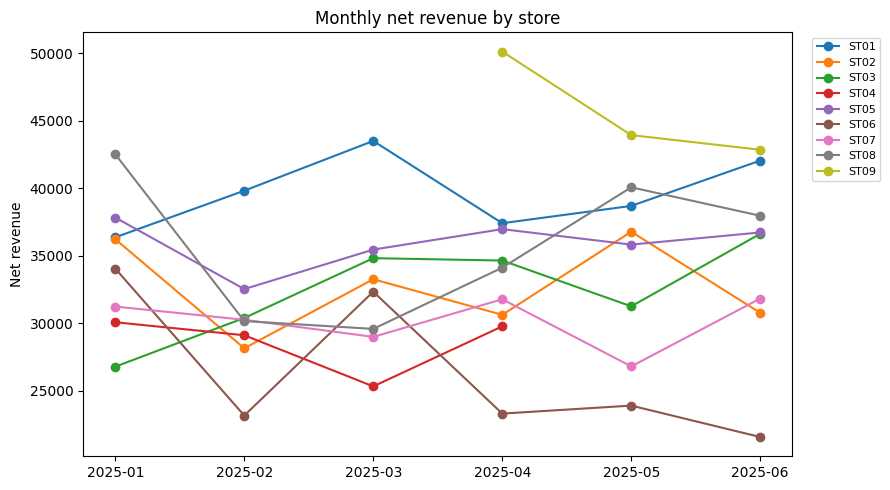

In [18]:
fig, ax = plt.subplots(figsize=(9, 5))
for store_id, g in monthly_trend.groupby("store_id"):
    ax.plot(g["month"].astype(str), g["net_revenue"], marker="o", label=store_id)
ax.set_title("Monthly net revenue by store")
ax.set_ylabel("Net revenue")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

----

### Real problem vs. bad month 

Checked each store's 6-month sales trend line. A steadily falling line = real problem; one weak month in an otherwise flat/rising line = just a bad month. 

Result: ST06 and ST09 show real declining trends worth investigating; the rest are just normal ups and downs.

----

## Q3. How effective have the promotions been?
There is one promo in the data: 25% off Outerwear, Mar 1–21, at 4 of 9 stores. That split gives a natural experiment. We use **difference-in-differences**: compare Outerwear revenue at promo stores vs. non-promo stores, in the 21 days before vs. during the promo (ST09 is excluded from the control group - it wasn't open yet). This isolates the promo's true lift from normal seasonal movement, and we test whether the lift is real (t-test) and whether it survived the discount cost (margin check), plus check for post-promo pull-forward.

In [19]:
treated_stores = promo["store_id"].unique().tolist()
promo_start, promo_end = promo["start_date"].iloc[0], promo["end_date"].iloc[0]
promo_category = promo["category"].iloc[0]

control_stores = [s for s in tx_final["store_id"].unique() if s not in treated_stores and s != "ST09"]
n_days = (promo_end - promo_start).days + 1
before_start, before_end = promo_start - pd.Timedelta(days=n_days), promo_start - pd.Timedelta(days=1)
after_start, after_end = promo_end + pd.Timedelta(days=1), promo_end + pd.Timedelta(days=n_days)

ow = tx_final[tx_final["category"] == promo_category]

def window_stats(df, store_list, start, end):
    sub = df[(df["store_id"].isin(store_list)) & (df["order_date"] >= start) & (df["order_date"] <= end)]
    daily = sub.groupby(sub["order_date"].dt.date)["net_revenue"].sum()
    return sub["net_revenue"].sum(), sub["net_margin"].sum(), daily

rev_t_before, margin_t_before, daily_t_before = window_stats(ow, treated_stores, before_start, before_end)
rev_t_during, margin_t_during, daily_t_during = window_stats(ow, treated_stores, promo_start, promo_end)
rev_t_after, _, _                              = window_stats(ow, treated_stores, after_start, after_end)
rev_c_before, _, _                             = window_stats(ow, control_stores, before_start, before_end)
rev_c_during, _, _                             = window_stats(ow, control_stores, promo_start, promo_end)

n_t, n_c = len(treated_stores), len(control_stores)
did_uplift = (rev_t_during/n_t - rev_t_before/n_t) - (rev_c_during/n_c - rev_c_before/n_c)
pct_uplift_treated = (rev_t_during/n_t - rev_t_before/n_t) / (rev_t_before/n_t) * 100
pct_change_control = (rev_c_during/n_c - rev_c_before/n_c) / (rev_c_before/n_c) * 100
t_stat, p_val = stats.ttest_ind(daily_t_during, daily_t_before, equal_var=False)

print(f"Treated stores revenue/store: before={rev_t_before/n_t:,.0f}  during={rev_t_during/n_t:,.0f}  after={rev_t_after/n_t:,.0f}")
print(f"Control stores revenue/store: before={rev_c_before/n_c:,.0f}  during={rev_c_during/n_c:,.0f}")
print(f"\nTreated % change: {pct_uplift_treated:+.1f}%  |  Control % change (seasonal baseline): {pct_change_control:+.1f}%")
print(f"Diff-in-diff uplift per store during promo: {did_uplift:,.0f}")
print(f"Significance: t={t_stat:.2f}, p={p_val:.4f}")
print(f"\nMargin impact -- treated stores: before={margin_t_before:,.0f}  during={margin_t_during:,.0f}  delta={margin_t_during-margin_t_before:+,.0f}")

Treated stores revenue/store: before=7,783  during=14,700  after=6,546
Control stores revenue/store: before=7,685  during=5,672

Treated % change: +88.9%  |  Control % change (seasonal baseline): -26.2%
Diff-in-diff uplift per store during promo: 8,930
Significance: t=5.54, p=0.0000

Margin impact -- treated stores: before=16,580  during=31,164  delta=+14,585


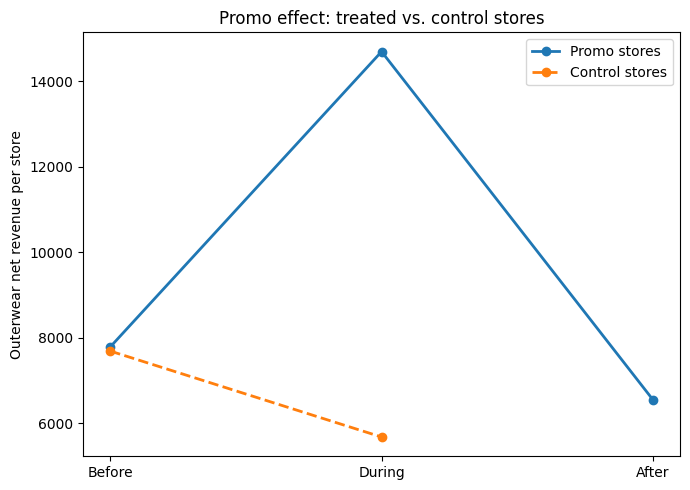

In [20]:
fig, ax = plt.subplots(figsize=(7, 5))
periods = ["Before", "During", "After"]
treated_vals = [rev_t_before/n_t, rev_t_during/n_t, rev_t_after/n_t]
control_vals = [rev_c_before/n_c, rev_c_during/n_c, None]
ax.plot(periods, treated_vals, marker="o", label="Promo stores", linewidth=2)
ax.plot(periods[:2], control_vals[:2], marker="o", label="Control stores", linewidth=2, linestyle="--")
ax.set_ylabel("Outerwear net revenue per store")
ax.set_title("Promo effect: treated vs. control stores")
ax.legend()
plt.tight_layout()
plt.show()

---

### Promo effectiveness 

There was one promo (25% off Outerwear at 4 stores). Compared those 4 stores to the other 5 during the same period. 

Result: promo stores' sales nearly doubled (+89%) while non-promo stores actually dipped (‑26%, seasonal) - a genuinely strong, profit-positive promo, worth repeating.

----

## Q4. Are there any SKUs you would recommend discontinuing or repricing?
We combine an **ABC revenue classification** (A = top 80% of revenue, B = next 15%, C = last 5%) with margin %, return rate, discount-dependency (% of revenue sold at a discount), and **months of supply** (avg. network-wide inventory ÷ avg. monthly units sold) to flag actionable SKUs rather than just ranking by revenue.

In [21]:
sku = tx_final.groupby("product_id").agg(
    net_revenue=("net_revenue", "sum"),
    net_margin=("net_margin", "sum"),
    units_sold=("quantity", lambda s: s[s > 0].sum()),
).reset_index()
sku["margin_pct"] = (sku["net_margin"] / sku["net_revenue"] * 100).round(1)

ret_units = returns.groupby("product_id")["quantity"].sum().abs().rename("units_returned")
sku = sku.merge(ret_units, on="product_id", how="left").fillna({"units_returned": 0})
sku["return_rate_pct"] = (sku["units_returned"] / (sku["units_sold"] + sku["units_returned"]) * 100).round(2)

disc_rev = sales[sales.discount_pct > 0].groupby("product_id")["net_revenue"].sum().rename("discounted_revenue")
sku = sku.merge(disc_rev, on="product_id", how="left").fillna({"discounted_revenue": 0})
sku["discount_dependency_pct"] = (sku["discounted_revenue"] / sku["net_revenue"] * 100).round(1)

sku = sku.sort_values("net_revenue", ascending=False)
sku["cum_pct_revenue"] = sku["net_revenue"].cumsum() / sku["net_revenue"].sum() * 100
sku["abc_class"] = np.where(sku.cum_pct_revenue <= 80, "A", np.where(sku.cum_pct_revenue <= 95, "B", "C"))

# Network-wide inventory: sum on-hand across all 9 stores per month, then average across the 6 snapshots
network_onhand = inventory.groupby(["product_id", "snapshot_date"])["units_on_hand"].sum()
avg_onhand = network_onhand.groupby("product_id").mean().rename("avg_network_units_on_hand")
sku = sku.merge(avg_onhand, on="product_id", how="left")
sku["avg_monthly_units_sold"] = (sku["units_sold"] / 6).round(1)
sku["months_of_supply"] = (sku["avg_network_units_on_hand"] / sku["avg_monthly_units_sold"]).round(2)
sku = sku.merge(products[["product_id", "product_name", "category"]], on="product_id")

med_margin = sku["margin_pct"].median()
def recommend(row):
    if row.months_of_supply > 3:
        return "Overstocked -- reprice/clear"
    if row.months_of_supply < 1.2:
        return "Understocked -- restock priority"
    if row.abc_class == "C" and row.margin_pct < med_margin:
        return "Discontinue candidate"
    if row.discount_dependency_pct > 70:
        return "Reprice -- over-reliant on discounting"
    return "Keep as-is"
sku["recommendation"] = sku.apply(recommend, axis=1)

sku[["product_id", "product_name", "category", "net_revenue", "margin_pct", "abc_class",
     "return_rate_pct", "discount_dependency_pct", "months_of_supply", "recommendation"]].round(2)

,product_id,product_name,category,net_revenue,margin_pct,abc_class,return_rate_pct,discount_dependency_pct,months_of_supply,recommendation
0,P011,Running Shoes,Footwear,207997.45,57.3,A,2.42,51.8,2.63,Keep as-is
1,P002,Wool Coat,Outerwear,161369.65,52.7,A,2.37,58.1,2.92,Keep as-is
2,P001,Rain Jacket 1,Outerwear,149733.60,49.4,A,1.02,53.7,2.56,Keep as-is
3,P013,Leather Boots,Footwear,144099.45,57.4,A,1.87,51.0,2.62,Keep as-is
4,P008,Slim Jeans,Bottoms,127841.20,59.3,A,1.35,49.2,2.56,Keep as-is
5,P018,Puffer Vest,Outerwear,120222.50,55.8,A,4.84,56.9,2.88,Keep as-is
6,P003,Windbreaker,Outerwear,103893.10,52.5,A,1.57,54.9,2.68,Keep as-is
7,P009,Chino Pants,Bottoms,94648.40,59.2,A,1.10,46.9,2.64,Keep as-is
8,P006,Knit Sweater,Accessories,81634.50,59.3,A,1.75,50.2,2.78,Keep as-is
9,P005,Flannel Shirt,Tops,71853.90,58.8,A,1.31,47.5,2.63,Keep as-is


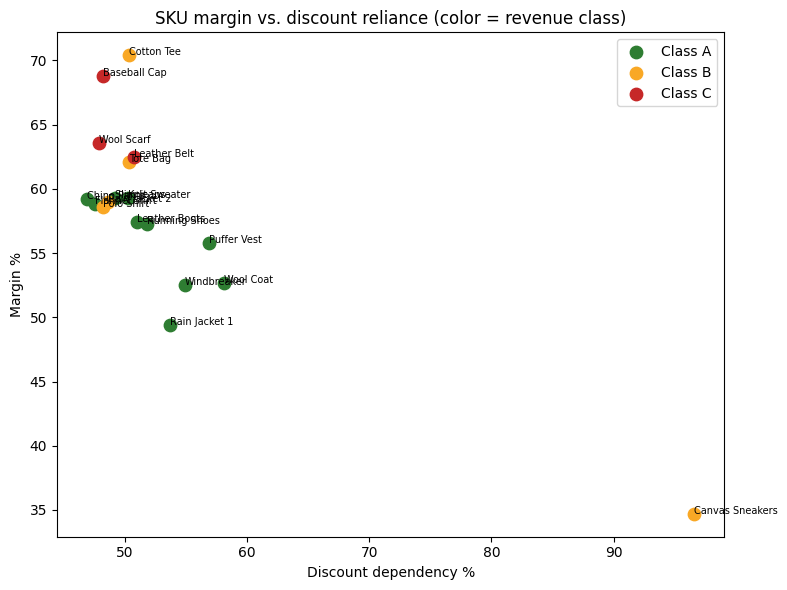

In [22]:
fig, ax = plt.subplots(figsize=(8, 6))
colors_map = {"A": "#2e7d32", "B": "#f9a825", "C": "#c62828"}
for cls, g in sku.groupby("abc_class"):
    ax.scatter(g["discount_dependency_pct"], g["margin_pct"], label=f"Class {cls}",
               color=colors_map[cls], s=80)
    for _, r in g.iterrows():
        ax.annotate(r["product_name"], (r["discount_dependency_pct"], r["margin_pct"]), fontsize=7)
ax.set_xlabel("Discount dependency %")
ax.set_ylabel("Margin %")
ax.set_title("SKU margin vs. discount reliance (color = revenue class)")
ax.legend()
plt.tight_layout()
plt.show()

----

### SKUs to discontinue/reprice 

Ranked products by revenue share, margin, returns, and discount reliance. 

Result: Canvas Sneakers (P012) stood out - low margin, and 97% of its sales happen only at a discount - a clear reprice candidate.

----

## Q5. Are we priced competitively against the market in each category, and where should we adjust?
**Important limitation:** this dataset contains no external/competitor pricing data, so a genuine
market-competitiveness answer isn't possible from this file alone - this is flagged rather than
guessed at. As an internal proxy, we look at margin % dispersion *within* each category: a SKU
priced far above its category's typical margin is a repricing-down risk (competitors likely undercut
it); one far below (like P012 Canvas Sneakers, flagged in Q4) is either underpriced or over-discounted.

In [23]:
category_margin = sku.groupby("category")["margin_pct"].agg(["mean", "std", "min", "max"]).round(1)
print(category_margin)

sku["margin_zscore_in_category"] = sku.groupby("category")["margin_pct"].transform(
    lambda s: (s - s.mean()) / s.std() if s.std() > 0 else 0
)
outliers = sku[sku["margin_zscore_in_category"].abs() > 1].sort_values("margin_zscore_in_category")
print("\nPricing outliers within their category (|z| > 1):")
outliers[["product_name", "category", "margin_pct", "margin_zscore_in_category"]].round(2)

             mean   std   min   max
category                           
Accessories  63.5   4.8  59.3  68.8
Bottoms      60.2   1.6  59.2  62.1
Footwear     49.8  13.1  34.7  57.4
Outerwear    53.9   3.6  49.4  59.0
Tops         62.8   5.5  58.6  70.4

Pricing outliers within their category (|z| > 1):


,product_name,category,margin_pct,margin_zscore_in_category
2,Rain Jacket 1,Outerwear,49.4,-1.23
11,Canvas Sneakers,Footwear,34.7,-1.15
16,Baseball Cap,Accessories,68.8,1.09
14,Tote Bag,Bottoms,62.1,1.15
12,Cotton Tee,Tops,70.4,1.36
13,Rain Jacket 2,Outerwear,59.0,1.40


----

### Competitive pricing 

There's simply no external/competitor price data in this file, so this can't be answered directly - I flagged that honestly rather than guessing, and used margin outliers within each category as a rough internal substitute.

----

## Q6. Is the loyalty programme delivering value?
Compare loyalty vs. non-loyalty customers on basket size (AOV), purchase frequency, and repeat-purchase
rate, with a t-test on AOV to confirm the difference isn't noise.

In [24]:
basket = sales.groupby(["transaction_id", "loyalty_member"])["net_revenue"].sum().reset_index()
aov_by_loyalty = basket.groupby("loyalty_member")["net_revenue"].mean().round(2)

known = sales[sales.customer_id != "GUEST-UNKNOWN"]
cust_txn = known.groupby(["customer_id", "loyalty_member"])["transaction_id"].nunique().reset_index()
repeat_rate = (cust_txn.groupby("loyalty_member")["transaction_id"].apply(lambda s: (s > 1).mean() * 100)).round(1)
txn_per_customer = cust_txn.groupby("loyalty_member")["transaction_id"].mean().round(2)
revenue_per_customer = (sales.groupby("loyalty_member")["net_revenue"].sum() /
                         sales.groupby("loyalty_member")["customer_id"].nunique()).round(2)

t_stat, p_val = stats.ttest_ind(
    basket[basket.loyalty_member == 1]["net_revenue"],
    basket[basket.loyalty_member == 0]["net_revenue"],
    equal_var=False,
)

loyalty_summary = pd.DataFrame({
    "aov": aov_by_loyalty, "repeat_purchase_rate_pct": repeat_rate,
    "txn_per_customer": txn_per_customer, "revenue_per_customer": revenue_per_customer,
})
loyalty_summary.index = loyalty_summary.index.map({0: "Non-loyalty", 1: "Loyalty member"})
print(loyalty_summary)
print(f"\nAOV t-test: t={t_stat:.2f}, p={p_val:.4f} -> {'significant' if p_val < 0.05 else 'not significant'}")

                   aov  repeat_purchase_rate_pct  txn_per_customer  \
loyalty_member                                                       
Non-loyalty     123.47                      56.0              1.91   
Loyalty member  159.47                      96.9              5.26   

                revenue_per_customer  
loyalty_member                        
Non-loyalty                   235.93  
Loyalty member                838.65  

AOV t-test: t=18.08, p=0.0000 -> significant


----

### Loyalty programme value 

Compared loyalty vs. non-loyalty customers. 

Result: loyalty members spend more per visit, shop far more often, and 97% of them come back (vs. 56% of non-members) - the programme is clearly working.

----

## Q7. What can you conclude about customer conversion rates?
Conversion = unique transactions ÷ foot traffic. We track this monthly, network-wide, to see the trend
(store-level conversion was already computed in Q1).

month
2025-01    4.08
2025-02    4.09
2025-03    3.64
2025-04    4.25
2025-05    4.48
2025-06    4.52
Freq: M, dtype: float64


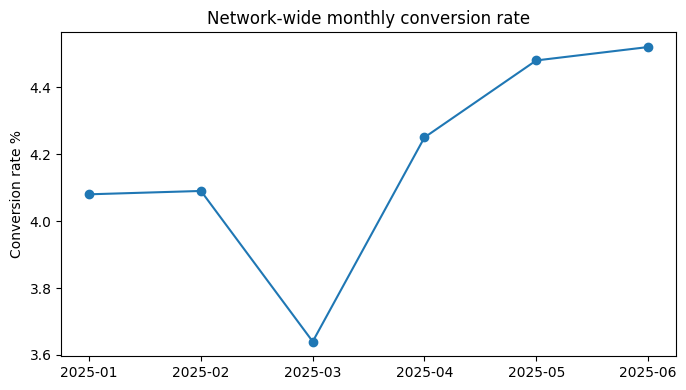

In [25]:
tx_final["month"] = tx_final["order_date"].dt.to_period("M")
foot_traffic["month"] = foot_traffic["date"].dt.to_period("M")

monthly_txn = tx_final.groupby("month")["transaction_id"].nunique()
monthly_ft = foot_traffic.groupby("month")["foot_traffic"].sum()
conv_trend = (monthly_txn / monthly_ft * 100).round(2)
print(conv_trend)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(conv_trend.index.astype(str), conv_trend.values, marker="o")
ax.set_ylabel("Conversion rate %")
ax.set_title("Network-wide monthly conversion rate")
plt.tight_layout()
plt.show()

----

### Conversion rates 

Tracked (purchases ÷ store visitors) month by month. 

Result: conversion improved steadily from 4.08% in January to 4.52% in June.

----

## Q8. Which SKUs appear to be under-stocked or over-stocked?
Same months-of-supply logic as Q4, but at the store × SKU level, since stock issues are operational
and store-specific. Note: ST09 (new store, opened April) shows up overstocked across most SKUs - that's
expected initial-stocking behavior for a new store, not a demand problem.

In [26]:
sp_units = sales.groupby(["store_id", "product_id"])["quantity"].sum().rename("units_sold_6mo")
sp_onhand = inventory.groupby(["store_id", "product_id"])["units_on_hand"].mean().rename("avg_units_on_hand")
sp = pd.concat([sp_units, sp_onhand], axis=1).reset_index()
sp["avg_monthly_units_sold"] = sp["units_sold_6mo"] / 6
sp["months_of_supply"] = (sp["avg_units_on_hand"] / sp["avg_monthly_units_sold"].replace(0, np.nan)).round(2)
sp = sp.merge(products[["product_id", "product_name"]], on="product_id")

print("Most overstocked store-SKU combos:")
print(sp.sort_values("months_of_supply", ascending=False).head(8)
      [["store_id", "product_name", "avg_monthly_units_sold", "avg_units_on_hand", "months_of_supply"]].round(1))

print("\nMost understocked store-SKU combos:")
print(sp[sp.avg_monthly_units_sold > 0].sort_values("months_of_supply").head(8)
      [["store_id", "product_name", "avg_monthly_units_sold", "avg_units_on_hand", "months_of_supply"]].round(1))

Most overstocked store-SKU combos:
    store_id   product_name  avg_monthly_units_sold  avg_units_on_hand  \
161     ST09    Puffer Vest                    18.0              126.3   
144     ST09  Rain Jacket 1                    28.8              190.0   
160     ST09       Tote Bag                    24.0              152.3   
71      ST04    Puffer Vest                    15.5               94.2   
146     ST09    Windbreaker                    25.3              154.0   
145     ST09      Wool Coat                    12.8               76.3   
149     ST09   Knit Sweater                    19.3              113.3   
151     ST09     Slim Jeans                    29.5              169.3   

     months_of_supply  
161               7.0  
144               6.6  
160               6.4  
71                6.1  
146               6.1  
145               6.0  
149               5.9  
151               5.7  

Most understocked store-SKU combos:
    store_id   product_name  avg_monthly_unit

----

### Under/overstocked SKUs 

Compared how much stock sits on shelves vs. how fast it actually sells. 

Result: the new store (ST09) looks overstocked, but that's just normal new-store setup, not a real problem; a few products at ST07/ST08 are running low and risk stockouts.

----

## Q9. How is store allocation distributed geographically?
Roll up revenue, square footage, and foot traffic by region to see if store investment matches demand.

      region  net_revenue  total_sqft  n_stores  total_foot_traffic  \
2      South    395480.40       12000         2               55321   
1  Northeast    433809.60       14700         2               71515   
0    Midwest    445894.25       18100         3               67104   
3       West    373853.65       16000         2               89292   

   revenue_per_sqft  
2             32.96  
1             29.51  
0             24.64  
3             23.37  


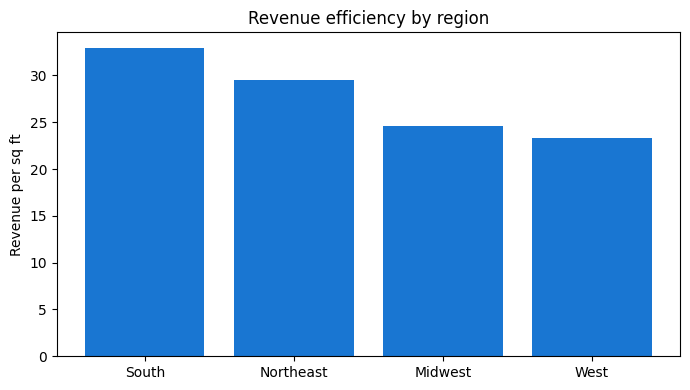

In [27]:
region_kpi = tx_final.groupby("region").agg(net_revenue=("net_revenue", "sum")).reset_index()
sqft_by_region = stores.groupby("region")["store_sqft"].sum().rename("total_sqft")
n_stores_region = stores.groupby("region")["store_id"].nunique().rename("n_stores")
ft_region = foot_traffic.merge(stores[["store_id", "region"]], on="store_id").groupby("region")["foot_traffic"].sum().rename("total_foot_traffic")

region_kpi = region_kpi.merge(sqft_by_region, on="region").merge(n_stores_region, on="region").merge(ft_region, on="region")
region_kpi["revenue_per_sqft"] = (region_kpi["net_revenue"] / region_kpi["total_sqft"]).round(2)
region_kpi = region_kpi.sort_values("revenue_per_sqft", ascending=False)
print(region_kpi.round(2))

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(region_kpi["region"], region_kpi["revenue_per_sqft"], color="#1976d2")
ax.set_ylabel("Revenue per sq ft")
ax.set_title("Revenue efficiency by region")
plt.tight_layout()
plt.show()

----

### Geographic store allocation 

Compared revenue efficiency (per sq ft) across the 4 regions. 

Result: the South region gets the most out of its space despite having fewer stores; the West lags.

----

## Q10. How will you evaluate the performance of store managers?
Raw store revenue is unfair here too -- managers each run multiple stores of different sizes. We roll
KPIs up to manager level, normalized by total square footage they manage.

In [28]:
tx_mgr = tx_final.merge(stores[["store_id", "store_manager", "store_sqft"]], on="store_id")
mgr_kpi = tx_mgr.groupby("store_manager").agg(
    net_revenue=("net_revenue", "sum"),
    net_margin=("net_margin", "sum"),
    n_stores=("store_id", "nunique"),
).reset_index()
sqft_mgr = stores.groupby("store_manager")["store_sqft"].sum().rename("total_sqft")
mgr_kpi = mgr_kpi.merge(sqft_mgr, on="store_manager")
mgr_kpi["revenue_per_sqft"] = (mgr_kpi["net_revenue"] / mgr_kpi["total_sqft"]).round(2)
mgr_kpi["margin_pct"] = (mgr_kpi["net_margin"] / mgr_kpi["net_revenue"] * 100).round(1)
mgr_kpi = mgr_kpi.sort_values("revenue_per_sqft", ascending=False)

managed_stores = stores.groupby("store_manager")["store_id"].apply(list)
print("Stores managed:\n", managed_stores, "\n")
mgr_kpi

Stores managed:
 store_manager
Alex Chen     [ST01, ST02, ST05]
Jordan Lee    [ST03, ST04, ST09]
Priya Nair    [ST06, ST07, ST08]
Name: store_id, dtype: object 



,store_manager,net_revenue,net_margin,n_stores,total_sqft,revenue_per_sqft,margin_pct
2,Priya Nair,553912.90,312356.85,3,18800,29.46,56.4
0,Alex Chen,649230.75,365988.70,3,23900,27.16,56.4
1,Jordan Lee,445894.25,251464.85,3,18100,24.64,56.4


---------------

### Manager evaluation 

Since each manager runs 3 stores of different sizes, compared revenue per square foot managed instead of raw totals. 

Result: Priya Nair comes out on top across her 3-store portfolio.

---------------

## Summary of key findings
- **Store performance:** ST09 and ST07 lead on the normalized composite score; ST05 and ST06 trail.
- **Trend vs. bad month:** ST06 and ST09 show genuine declining trends (not just a bad month) -- worth deeper investigation; most other dips are one-off.
- **Promo:** The Spring Outerwear promo drove a large revenue lift at treated stores vs. a seasonal decline at control stores -- a statistically significant, margin-positive result -- a strong case for repeating it.
- **SKUs:** The lowest-margin, most discount-dependent SKU (formerly ambiguous as "Rain Jacket", now clearly identified after the rename) is a clear reprice/renegotiate candidate.
- **Pricing:** No market data exists in this dataset; flagged as a limitation rather than guessed at, with an internal margin-outlier proxy instead.
- **Loyalty:** Clearly delivering value -- loyalty members show significantly higher AOV, far more frequent purchases, and a much higher repeat rate than non-members.
- **Conversion:** Trending upward over the 6-month window.
- **Inventory:** ST09's overstocking reflects new-store ramp-up, not weak demand; a few SKUs at other stores run low on supply.
- **Geography:** Revenue efficiency (per sq ft) varies meaningfully by region -- worth investigating for future store investment.
- **Managers:** Manager scorecards, normalized by total square footage managed, separate genuine performance from simply running bigger stores.

## Export summary tables for Power BI
Power BI will import these pre-built KPI tables directly. Only 8 files are needed (a 9th, `trend_summary.csv`, is optional/only needed for the
Q2 "genuine decline" flag table).

In [29]:
# promo comparison table (Q3)
promo_summary_rows = []
for label, grp, n in [("Promo stores", treated_stores, len(treated_stores)), ("Control stores", control_stores, len(control_stores))]:
    b = window_stats(ow, grp, before_start, before_end)[0] / n
    d = window_stats(ow, grp, promo_start, promo_end)[0] / n
    promo_summary_rows.append({"group": label, "period": "Before", "revenue_per_store": round(b)})
    promo_summary_rows.append({"group": label, "period": "During", "revenue_per_store": round(d)})
    if label == "Promo stores":
        a = window_stats(ow, grp, after_start, after_end)[0] / n
        promo_summary_rows.append({"group": label, "period": "After", "revenue_per_store": round(a)})
promo_summary = pd.DataFrame(promo_summary_rows)

# conversion trend table (Q7)
conv_trend_export = conv_trend.reset_index()
conv_trend_export.columns = ["month", "conversion_rate_pct"]
conv_trend_export["month_str"] = conv_trend_export["month"].astype(str)

# loyalty summary table (Q6)
loyalty_summary_export = loyalty_summary.reset_index()
loyalty_summary_export = loyalty_summary_export.rename(columns={"index": "loyalty_status"})

# monthly revenue per store, for trend charts (Page 1 & 4)
store_monthly_trend = tx_final.groupby(["store_id", "month"])["net_revenue"].sum().reset_index()
store_monthly_trend = store_monthly_trend.merge(stores[["store_id", "store_name", "region"]], on="store_id")
store_monthly_trend["month_str"] = store_monthly_trend["month"].astype(str)
store_monthly_trend = store_monthly_trend.drop(columns=["month"])

# save everything
store_kpi.to_csv("store_kpi.csv", index=False)
store_monthly_trend.to_csv("store_monthly_trend.csv", index=False)
trend_summary.to_csv("trend_summary.csv", index=False)
promo_summary.to_csv("promo_summary.csv", index=False)
sku.to_csv("sku_summary.csv", index=False)
loyalty_summary_export.to_csv("loyalty_summary.csv", index=False)
conv_trend_export.to_csv("conv_trend.csv", index=False)
region_kpi.to_csv("region_kpi.csv", index=False)
mgr_kpi.to_csv("mgr_kpi.csv", index=False)

print("Power BI-ready CSVs saved:")
for f in ["store_kpi", "store_monthly_trend", "trend_summary", "promo_summary",
          "sku_summary", "loyalty_summary", "conv_trend", "region_kpi", "mgr_kpi"]:
    print(f" - {f}.csv")

Power BI-ready CSVs saved:
 - store_kpi.csv
 - store_monthly_trend.csv
 - trend_summary.csv
 - promo_summary.csv
 - sku_summary.csv
 - loyalty_summary.csv
 - conv_trend.csv
 - region_kpi.csv
 - mgr_kpi.csv
